In [1]:

# Installation des bibliothèques nécessaires
!pip install -q torch scikit-learn seaborn pandas matplotlib kagglehub imbalanced-learn

# Manipulation des données
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Deep Learning
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Prétraitement et évaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())


PyTorch : 2.11.0+cpu
GPU disponible : False


# **Partie 1: Régression avec le dataset NYSE**



**Télécharger et comprendre le dataset**

In [2]:

import kagglehub
import os

# Télécharger le dataset NYSE
path = kagglehub.dataset_download("dgawlik/nyse")

print("Dossier téléchargé :", path)

# Afficher les fichiers disponibles
for root, dirs, files in os.walk(path):
    for file in files:
        print(file)


Using Colab cache for faster access to the 'nyse' dataset.
Dossier téléchargé : /kaggle/input/nyse
prices-split-adjusted.csv
fundamentals.csv
prices.csv
securities.csv


Charge ensuite le fichier des prix ajustés

In [3]:

import os

file_path = os.path.join(path, "prices-split-adjusted.csv")
df = pd.read_csv(file_path)

print(df.head())
print("Dimensions :", df.shape)
print("Colonnes :", df.columns.tolist())


         date symbol        open       close         low        high  \
0  2016-01-05   WLTW  123.430000  125.839996  122.309998  126.250000   
1  2016-01-06   WLTW  125.239998  119.980003  119.940002  125.540001   
2  2016-01-07   WLTW  116.379997  114.949997  114.930000  119.739998   
3  2016-01-08   WLTW  115.480003  116.620003  113.500000  117.440002   
4  2016-01-11   WLTW  117.010002  114.970001  114.089996  117.330002   

      volume  
0  2163600.0  
1  2386400.0  
2  2489500.0  
3  2006300.0  
4  1408600.0  
Dimensions : (851264, 7)
Colonnes : ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']


**Réaliser l'EDA (Exploratory Data Analysis)**

Examiner la structure et les statistiques

In [4]:

print(df.info())
print(df.describe(include="all").T)
print("Valeurs manquantes :")
print(df.isnull().sum())
print("Lignes dupliquées :", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB
None
           count unique         top  freq            mean              std  \
date      851264   1762  2016-12-29   501             NaN              NaN   
symbol    851264    501         AIV  1762             NaN              NaN   
open    851264.0    NaN         NaN   NaN       64.993618        75.203893   
close   851264.0    NaN         NaN   NaN       65.011913        75.201216   
low     851264.0    NaN         NaN   NaN       64.336541        74.459518   
high    851264.0    Na

Visualiser les distributions

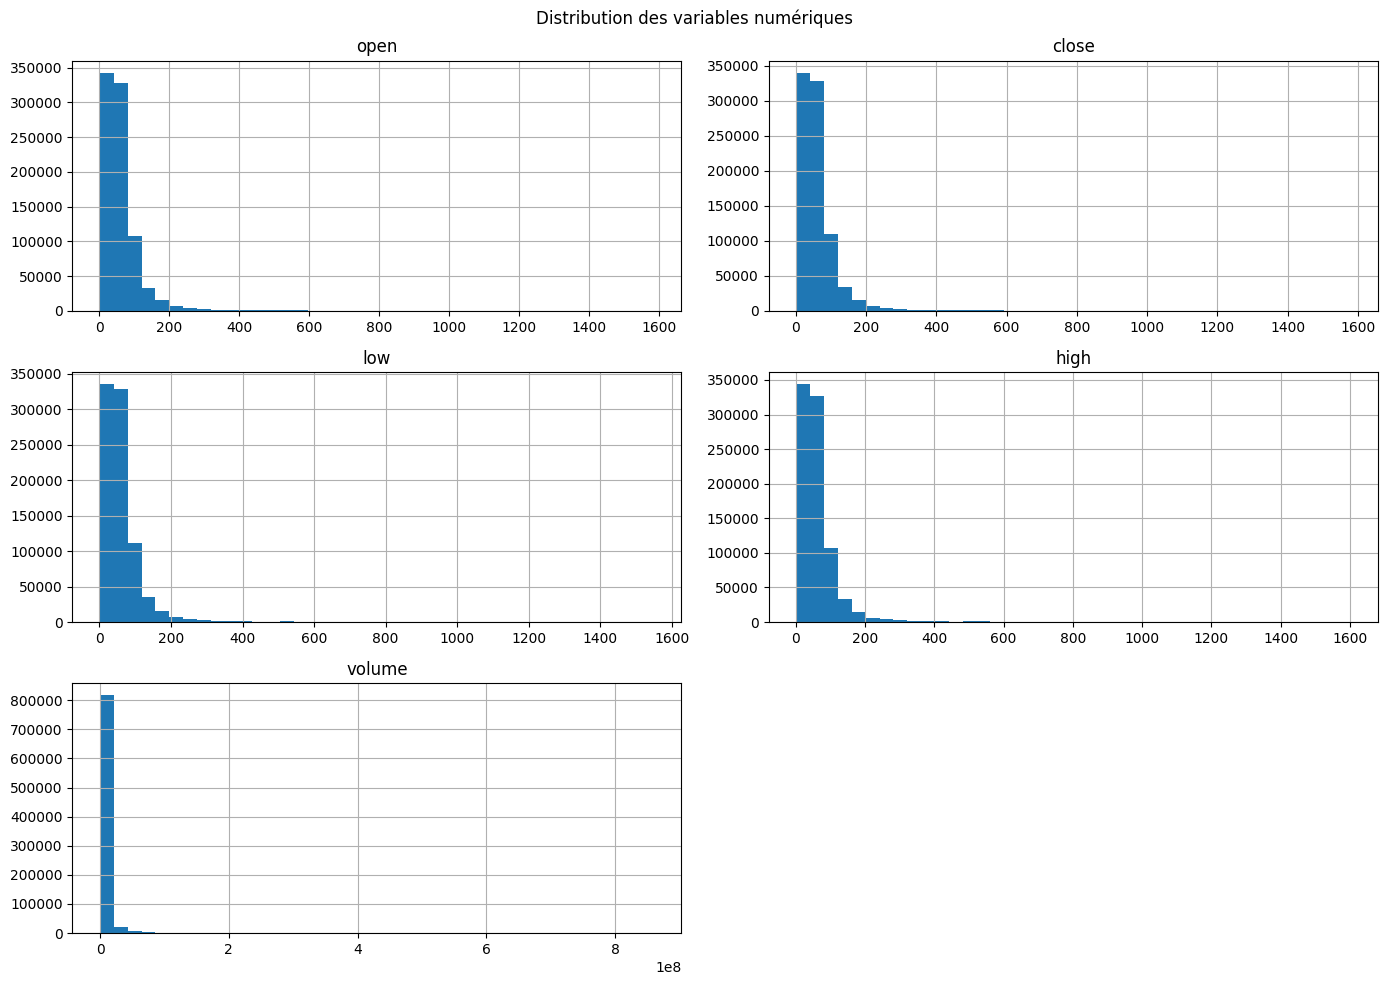

In [5]:

df.select_dtypes(include="number").hist(
    figsize=(14, 10), bins=40
)
plt.suptitle("Distribution des variables numériques")
plt.tight_layout()
plt.show()


Examiner les corrélations

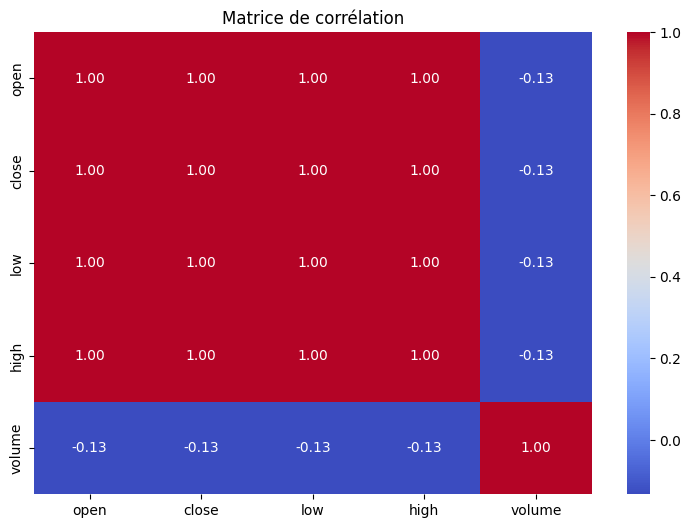

In [6]:

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Matrice de corrélation")
plt.show()


**Préparer les données pour la régression**

Pour commencer, nous allons utiliser une seule action, par exemple AAPL, afin de rendre l'exercice plus simple. Nous utiliserons open, high, low et volume pour prédire close.

In [7]:

# Nettoyage de base
df["date"] = pd.to_datetime(df["date"])

# Choisir une action
stock = df[df["symbol"] == "AAPL"].copy()

# Trier chronologiquement
stock = stock.sort_values("date")

features = ["open", "high", "low", "volume"]
target = "close"

stock = stock.dropna(subset=features + [target])
stock = stock[(stock[features + [target]] >= 0).all(axis=1)]

X = stock[features]
y = stock[target]

print("Nombre d'observations :", len(stock))
print(stock.head())


Nombre d'observations : 1762
           date symbol       open      close        low       high  \
254  2010-01-04   AAPL  30.490000  30.572857  30.340000  30.642857   
721  2010-01-05   AAPL  30.657143  30.625713  30.464285  30.798571   
1189 2010-01-06   AAPL  30.625713  30.138571  30.107143  30.747143   
1657 2010-01-07   AAPL  30.250000  30.082857  29.864286  30.285715   
2125 2010-01-08   AAPL  30.042856  30.282858  29.865715  30.285715   

           volume  
254   123432400.0  
721   150476200.0  
1189  138040000.0  
1657  119282800.0  
2125  111902700.0  


In [8]:

n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

# Standardisation : apprendre uniquement sur le train
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)


Train : (1233, 4)
Validation : (264, 4)
Test : (265, 4)


**Construire le réseau de neurones PyTorch**

In [9]:

# Conversion des données en tenseurs PyTorch
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_t = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_val_t = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_test_t = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)


class MLPRegressor(nn.Module):
    def __init__(self, input_dim, hidden1=64, hidden2=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)


model = MLPRegressor(input_dim=len(features))
print(model)


MLPRegressor(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


**Entraîner le modèle**

In [10]:

from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=64,
    shuffle=True
)

model = MLPRegressor(input_dim=len(features))
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 100
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()

        predictions = model(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    train_loss = total_loss / len(X_train_t)

    model.eval()
    with torch.no_grad():
        val_predictions = model(X_val_t)
        val_loss = criterion(val_predictions, y_val_t).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )


Epoch 10/100 | Train Loss: 661.9589 | Val Loss: 1851.8408
Epoch 20/100 | Train Loss: 195.4845 | Val Loss: 1565.9176
Epoch 30/100 | Train Loss: 65.9680 | Val Loss: 462.0107
Epoch 40/100 | Train Loss: 18.7399 | Val Loss: 137.6706
Epoch 50/100 | Train Loss: 5.6051 | Val Loss: 45.4535
Epoch 60/100 | Train Loss: 1.9536 | Val Loss: 8.8496
Epoch 70/100 | Train Loss: 1.1401 | Val Loss: 5.0630
Epoch 80/100 | Train Loss: 0.8896 | Val Loss: 4.0246
Epoch 90/100 | Train Loss: 0.7554 | Val Loss: 3.5870
Epoch 100/100 | Train Loss: 0.6747 | Val Loss: 2.8200


**Tracer Loss / Epochs**

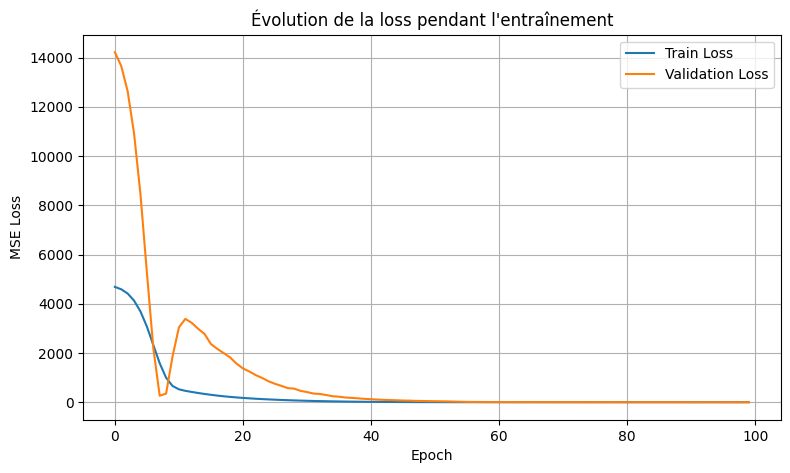

In [11]:

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Évolution de la loss pendant l'entraînement")
plt.legend()
plt.grid(True)
plt.show()


**Évaluer le modèle sur le test**

In [12]:
print(X_train.describe())
print("Valeurs maximales absolues :")
print(X_train.abs().max())

              open         high          low        volume
count  1233.000000  1233.000000  1233.000000  1.233000e+03
mean     65.284084    65.872252    64.621452  1.152263e+08
std      20.784156    20.942896    20.632290  5.945669e+07
min      27.481428    28.000000    27.178572  2.289180e+07
25%      48.745716    49.128571    48.162857  7.355600e+07
50%      64.279999    64.928574    63.389999  1.018206e+08
75%      81.272858    81.824287    80.175713  1.431633e+08
max     117.510002   118.769997   116.620003  4.702495e+08
Valeurs maximales absolues :
open      1.175100e+02
high      1.187700e+02
low       1.166200e+02
volume    4.702495e+08
dtype: float64


In [13]:

model.eval()

with torch.no_grad():
    y_pred = model(X_test_t).numpy().ravel()

y_true = y_test.to_numpy()

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print("MAE :", mae)
print("RMSE :", rmse)
print("R² :", r2)


MAE : 0.7255314049012384
RMSE : 0.9235506094429671
R² : 0.9848095665806497


**Tester les hyperparamètres avec GridSearch**

In [14]:
!pip install -q skorch

In [15]:
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Le modèle doit être recréé à chaque essai
net = NeuralNetRegressor(
    module=MLPRegressor,
    module__input_dim=X_train_scaled.shape[1],
    module__hidden1=64,
    module__hidden2=32,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    max_epochs=50,
    batch_size=32,
    lr=0.001,
    train_split=False,
    verbose=0,
    device="cpu"
)

# Hyperparamètres à comparer
param_grid = {
    "lr": [0.0001, 0.001],
    "optimizer": [torch.optim.Adam],
    "module__hidden1": [32, 64],
    "max_epochs": [50, 100],
    "batch_size": [32, 64]
}

# Validation chronologique
tscv = TimeSeriesSplit(n_splits=3)

grid = GridSearchCV(
    estimator=net,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=tscv,
    refit=True,
    n_jobs=1,
    verbose=1
)

# y doit avoir la forme (nombre d'observations, 1)
y_train_grid = y_train.to_numpy(
    dtype=np.float32
).reshape(-1, 1)

grid.fit(
    X_train_scaled.astype(np.float32),
    y_train_grid
)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur MSE de validation :", -grid.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Meilleurs paramètres : {'batch_size': 32, 'lr': 0.001, 'max_epochs': 100, 'module__hidden1': 64, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur MSE de validation : 580.6860968470573


évaluer le meilleur modèle trouvé par GridSearchCV


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_model = grid.best_estimator_

y_pred_grid = best_model.predict(
    X_test_scaled.astype(np.float32)
).reshape(-1)

y_true = y_test.to_numpy()

print("MAE :", mean_absolute_error(y_true, y_pred_grid))
print("RMSE :", np.sqrt(mean_squared_error(y_true, y_pred_grid)))
print("R² :", r2_score(y_true, y_pred_grid))

MAE : 0.6395241909898288
RMSE : 0.8844635250282671
R² : 0.9860681553875512


**la régularisation**

Créer une architecture avec Dropout

In [17]:
class MLPRegressorRegularized(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden1=64,
        hidden2=32,
        dropout=0.2
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)

Créer une fonction d'entraînement réutilisable

In [18]:
def train_regression_model(
    model,
    X_train_t,
    y_train_t,
    X_val_t,
    y_val_t,
    epochs=100,
    weight_decay=0.0
):
    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=32,
        shuffle=False
    )

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for xb, yb in loader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(xb)

        history["train_loss"].append(
            total_loss / len(X_train_t)
        )

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            val_loss = criterion(
                val_pred, y_val_t
            ).item()

        history["val_loss"].append(val_loss)

    return model, history

Entraîner et comparer les trois modèles

In [19]:
torch.manual_seed(42)

# 1. Modèle de base
baseline = MLPRegressor(
    input_dim=X_train_t.shape[1]
)

baseline, hist_base = train_regression_model(
    baseline,
    X_train_t, y_train_t,
    X_val_t, y_val_t,
    epochs=100
)

# 2. Modèle avec Dropout
dropout_model = MLPRegressorRegularized(
    input_dim=X_train_t.shape[1],
    dropout=0.2
)

dropout_model, hist_dropout = train_regression_model(
    dropout_model,
    X_train_t, y_train_t,
    X_val_t, y_val_t,
    epochs=100
)

# 3. Modèle avec Weight decay (L2)
l2_model = MLPRegressor(
    input_dim=X_train_t.shape[1]
)

l2_model, hist_l2 = train_regression_model(
    l2_model,
    X_train_t, y_train_t,
    X_val_t, y_val_t,
    epochs=100,
    weight_decay=1e-4
)

Comparer les courbes de loss

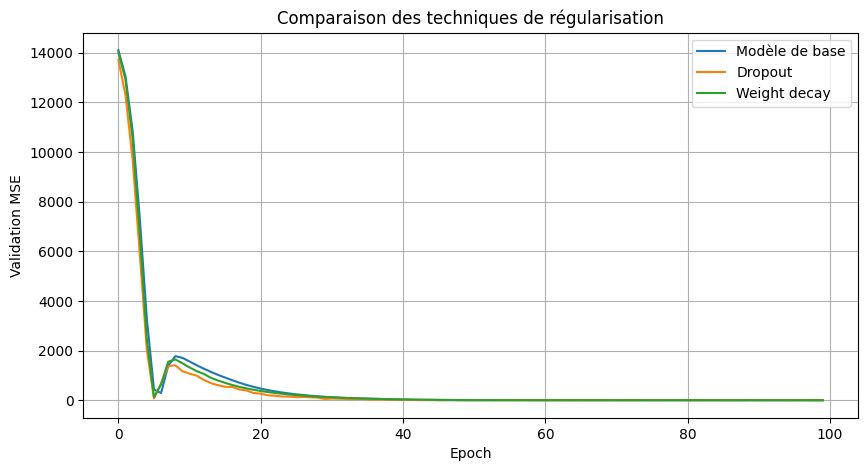

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    hist_base["val_loss"],
    label="Modèle de base"
)
plt.plot(
    hist_dropout["val_loss"],
    label="Dropout"
)
plt.plot(
    hist_l2["val_loss"],
    label="Weight decay"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Comparaison des techniques de régularisation")
plt.legend()
plt.grid(True)
plt.show()

Comparer les résultats sur le test

In [21]:
def evaluate_regression(model, X_test_t, y_test_t):
    model.eval()

    with torch.no_grad():
        predictions = model(X_test_t).numpy().ravel()

    actual = y_test_t.numpy().ravel()

    return {
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predictions)
        ),
        "R2": r2_score(actual, predictions)
    }


results = pd.DataFrame({
    "Base": evaluate_regression(
        baseline, X_test_t, y_test_t
    ),
    "Dropout": evaluate_regression(
        dropout_model, X_test_t, y_test_t
    ),
    "Weight decay": evaluate_regression(
        l2_model, X_test_t, y_test_t
    )
}).T

print(results)

                   MAE      RMSE        R2
Base          0.610996  0.802892  0.988519
Dropout       1.853319  2.002423  0.928590
Weight decay  0.627697  0.825982  0.987850


# Partie 2 : classification avec PyTorch

**Installation et imports**

In [22]:
import kagglehub
import os
import pandas as pd

# Télécharger le dataset de classification
path_clf = kagglehub.dataset_download(
    "shivamb/machine-predictive-maintenance-classification"
)

print("Dossier téléchargé :", path_clf)

# Rechercher les fichiers CSV
csv_files = []

for root, dirs, files in os.walk(path_clf):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("Fichiers CSV trouvés :", csv_files)

100%|██████████| 137k/137k [00:00<00:00, 36.4MB/s]

Extracting files...
Dossier téléchargé : /root/.cache/kagglehub/datasets/shivamb/machine-predictive-maintenance-classification/versions/1
Fichiers CSV trouvés : ['/root/.cache/kagglehub/datasets/shivamb/machine-predictive-maintenance-classification/versions/1/predictive_maintenance.csv']


In [23]:
# Charger le premier fichier CSV trouvé
df_clf = pd.read_csv(csv_files[0])

print("Dimensions :", df_clf.shape)
print("\nColonnes :")
print(df_clf.columns.tolist())

print("\nPremières lignes :")
display(df_clf.head())

print("\nInformations générales :")
df_clf.info()

print("\nValeurs manquantes :")
print(df_clf.isnull().sum())

print("\nTypes de panne :")
print(df_clf["Failure Type"].value_counts())

Dimensions : (10000, 10)

Colonnes :
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']

Premières lignes :


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure



Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB

Valeurs manquantes :
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperat

**EDA:Exploration des données**

Structure, statistiques et valeurs manquantes

In [24]:

print(df_clf.info())

print("\nStatistiques descriptives :")
display(df_clf.describe(include="all").T)

print("\nValeurs manquantes :")
print(df_clf.isnull().sum())

print("\nLignes dupliquées :", df_clf.duplicated().sum())

print("\nColonnes :")
print(df_clf.columns.tolist())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
None

Statistiques descriptives :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,L57163,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Target,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
Failure Type,10000,6,No Failure,9652,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Valeurs manquantes :
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

Lignes dupliquées : 0

Colonnes :
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


Distribution des catégories de panne

Répartition de Failure Type :
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


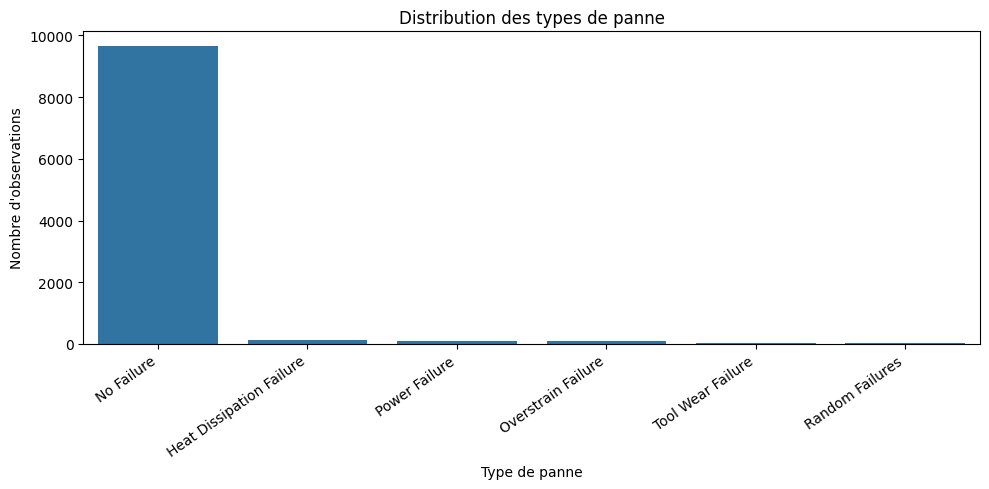

In [25]:
print("Répartition de Failure Type :")
print(df_clf["Failure Type"].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_clf,
    x="Failure Type",
    order=df_clf["Failure Type"].value_counts().index
)
plt.title("Distribution des types de panne")
plt.xlabel("Type de panne")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Distribution des variables numériques

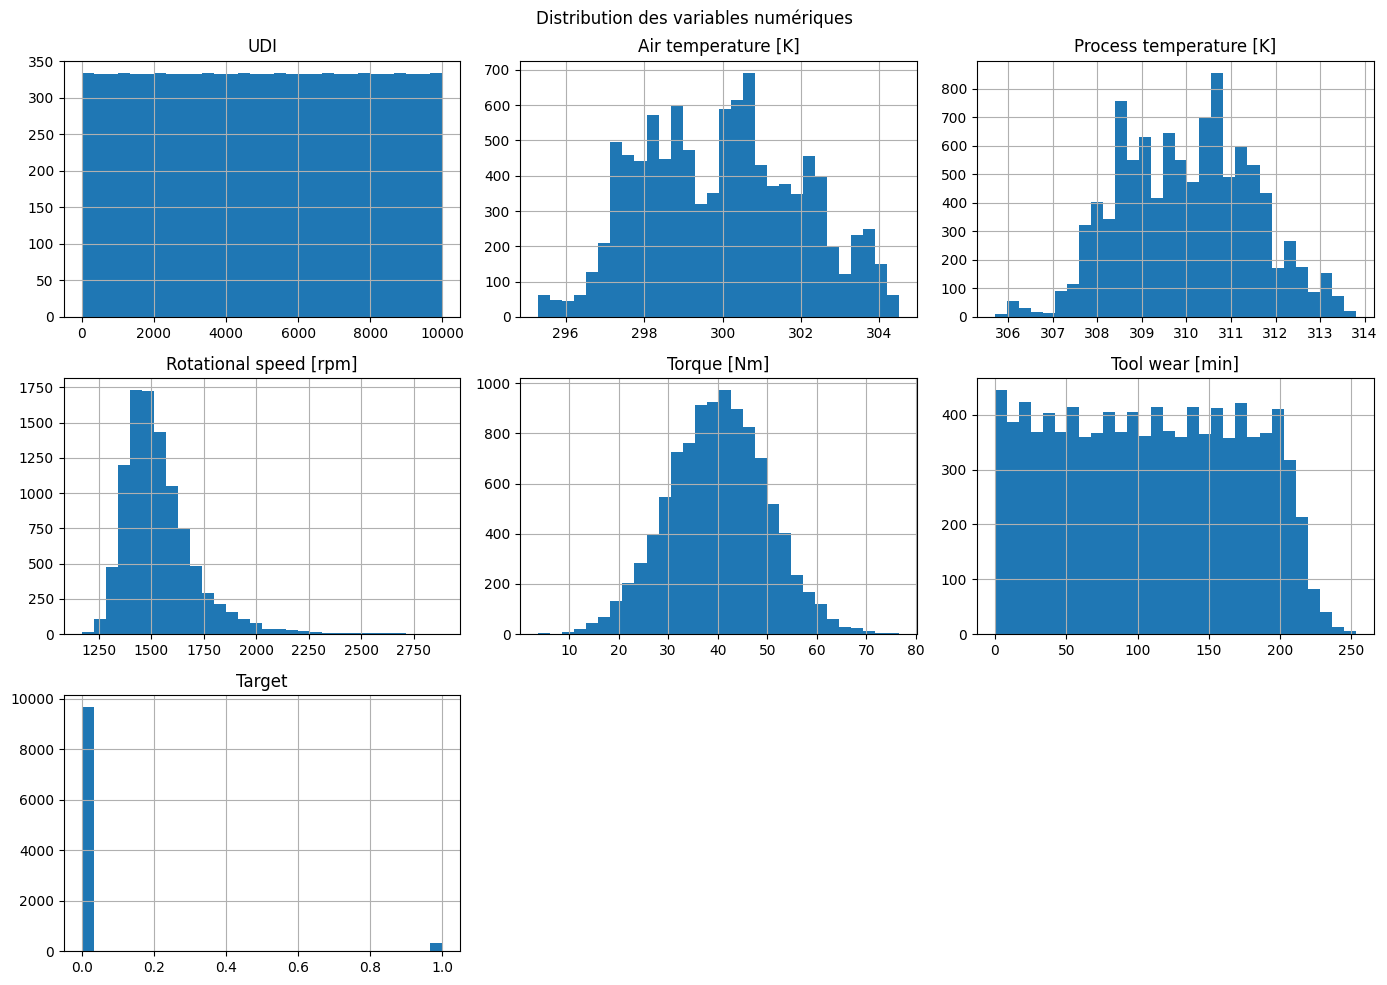

In [26]:
numeric_cols = df_clf.select_dtypes(include="number").columns

df_clf[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution des variables numériques")
plt.tight_layout()
plt.show()

Corrélations

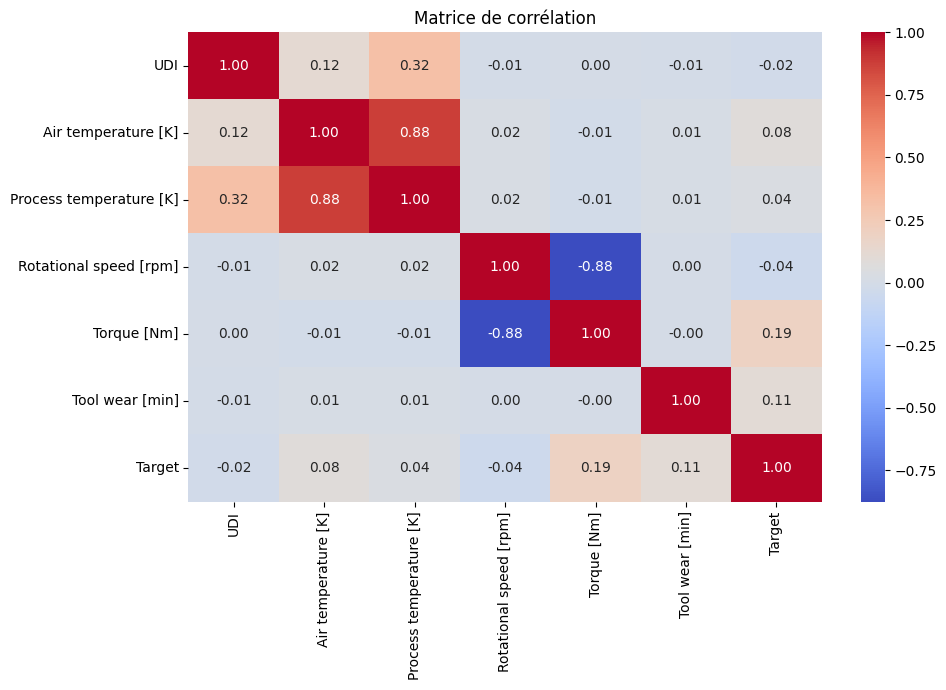

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clf[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

**Préparation des données**

Construire X et y

In [28]:
# Vérifier les colonnes attendues
required_columns = [
    "UDI", "Product ID", "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Target", "Failure Type"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clf.columns
]

if missing_columns:
    raise ValueError(f"Colonnes manquantes : {missing_columns}")

# Retirer les lignes avec valeurs manquantes
df_clf = df_clf.dropna(
    subset=[
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Failure Type"
    ]
).copy()

# Cible multiclasse
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df_clf["Failure Type"])

# Entrées : pas d'identifiants ni de cible secondaire
X_raw = df_clf.drop(
    columns=["UDI", "Product ID", "Target", "Failure Type"]
)

# Encodage de la variable catégorielle Type
X = pd.get_dummies(
    X_raw,
    columns=["Type"],
    dtype=float
)

print("Dimensions de X :", X.shape)
print("Nombre de classes :", len(label_encoder.classes_))
print("Classes :", list(label_encoder.classes_))
print("\nRépartition des classes :")
print(pd.Series(y).value_counts().sort_index())

Dimensions de X : (10000, 8)
Nombre de classes : 6
Classes : ['Heat Dissipation Failure', 'No Failure', 'Overstrain Failure', 'Power Failure', 'Random Failures', 'Tool Wear Failure']

Répartition des classes :
0     112
1    9652
2      78
3      95
4      18
5      45
Name: count, dtype: int64


Diviser les données

In [29]:
import random
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [30]:
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train :", X_train_raw.shape)
print("Validation :", X_val_raw.shape)
print("Test :", X_test_raw.shape)

Train : (7000, 8)
Validation : (1500, 8)
Test : (1500, 8)


Standardiser les variables

In [31]:
scaler_X_clf = StandardScaler()

X_train_scaled = scaler_X_clf.fit_transform(X_train_raw)
X_val_scaled = scaler_X_clf.transform(X_val_raw)
X_test_scaled = scaler_X_clf.transform(X_test_raw)

X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

y_train = np.asarray(y_train, dtype=np.int64)
y_val = np.asarray(y_val, dtype=np.int64)
y_test = np.asarray(y_test, dtype=np.int64)

print("Standardisation terminée.")
print("NaN :", np.isnan(X_train_scaled).any())
print("Infini :", np.isinf(X_train_scaled).any())

Standardisation terminée.
NaN : False
Infini : False


Traiter le déséquilibre des classes

In [32]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=SEED)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_scaled, y_train
)

print("Répartition après rééquilibrage :")
print(pd.Series(y_train_balanced).value_counts().sort_index())

print("Train équilibré :", X_train_balanced.shape)

Répartition après rééquilibrage :
0    6756
1    6756
2    6756
3    6756
4    6756
5    6756
Name: count, dtype: int64
Train équilibré : (40536, 8)


In [33]:
print("Répartition avant rééquilibrage :")
print(pd.Series(y_train).value_counts().sort_index())

ros = RandomOverSampler(random_state=SEED)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_scaled, y_train
)

print("\nRépartition après rééquilibrage :")
print(pd.Series(y_train_balanced).value_counts().sort_index())

print("Train équilibré :", X_train_balanced.shape)

Répartition avant rééquilibrage :
0      78
1    6756
2      55
3      67
4      13
5      31
Name: count, dtype: int64

Répartition après rééquilibrage :
0    6756
1    6756
2    6756
3    6756
4    6756
5    6756
Name: count, dtype: int64
Train équilibré : (40536, 8)


**Construire le réseau de neurones MLP**

In [34]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device utilisé :", device)

Device utilisé : cpu


In [35]:
class MLPClassifierTorch(nn.Module):
    def __init__(
        self,
        input_dim,
        output_dim,
        hidden1=64,
        hidden2=32,
        dropout=0.0
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden2, output_dim)
        )

    def forward(self, x):
        return self.network(x)

num_classes = len(np.unique(y_train))
input_dim = X_train_balanced.shape[1]
output_dim = num_classes

model = MLPClassifierTorch(
    input_dim=input_dim,
    output_dim=output_dim,
    hidden1=64,
    hidden2=32,
    dropout=0.0
).to(device)

print(model)

MLPClassifierTorch(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=6, bias=True)
  )
)


fonction d’entraînement avec Early Stopping

In [36]:
def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=100,
    batch_size=64,
    lr=0.001,
    weight_decay=0.0,
    patience=8
):
    train_tensor = torch.tensor(X_train, dtype=torch.float32)
    target_tensor = torch.tensor(y_train, dtype=torch.long)

    val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    val_target = torch.tensor(y_val, dtype=torch.long).to(device)

    loader = DataLoader(
        TensorDataset(train_tensor, target_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        correct = 0
        total = 0

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(yb)
            correct += (outputs.argmax(1) == yb).sum().item()
            total += len(yb)

        train_loss = loss_sum / total
        train_acc = correct / total

        model.eval()
        with torch.no_grad():
            val_outputs = model(val_tensor)
            val_loss = criterion(val_outputs, val_target).item()
            val_acc = (
                val_outputs.argmax(1) == val_target
            ).float().mean().item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            print(f"Early stopping à l'époque {epoch + 1}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

**Entraîner le modèle**

In [48]:
import copy

model = MLPClassifierTorch(
    input_dim=input_dim,
    output_dim=output_dim,
    hidden1=64,
    hidden2=32,
    dropout=0.0
).to(device)

model, history = train_model(
    model,
    X_train_balanced,
    y_train_balanced,
    X_val_scaled,
    y_val,
    epochs=100,
    batch_size=64,
    lr=0.001,
    weight_decay=0.0,
    patience=8
)

Early stopping à l'époque 23


**GridSearchCV : recherche des meilleurs hyperparamètres**

lancer GridSearchCV

In [49]:
from skorch import NeuralNetClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

# Le réseau utilisé par GridSearchCV
net = NeuralNetClassifier(
    module=MLPClassifierTorch,
    module__input_dim=input_dim,
    module__output_dim=output_dim,
    module__hidden2=32,
    module__dropout=0.0,
    criterion=nn.CrossEntropyLoss,
    max_epochs=20,
    batch_size=64,
    lr=0.001,
    optimizer=torch.optim.Adam,
    device=device,
    verbose=0
)

# IMPORTANT : le suréchantillonnage est inclus dans le pipeline.
# Il sera donc appliqué uniquement aux données d'entraînement de chaque pli.
pipeline = Pipeline([
    ("oversampler", RandomOverSampler(random_state=SEED)),
    ("net", net)
])

param_grid = {
    "net__lr": [0.001],
    "net__optimizer": [torch.optim.Adam],
    "net__max_epochs": [20],
    "net__batch_size": [64],
    "net__module__hidden1": [32, 64]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

# Utiliser les données d'entraînement ORIGINALES, non suréchantillonnées.
X_cv = np.asarray(X_train_scaled, dtype=np.float32)
y_cv = np.asarray(y_train, dtype=np.int64)

grid.fit(X_cv, y_cv)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur F1 macro CV :", grid.best_score_)


Fitting 3 folds for each of 2 candidates, totalling 6 fits
Meilleurs paramètres : {'batch_size': 64, 'lr': 0.001, 'max_epochs': 20, 'module__hidden1': 64, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur F1 macro CV : 0.7299432169114825


**entraîner le modèle avec les meilleurs paramètres**

In [50]:
# Récupérer les meilleurs hyperparamètres trouvés par le pipeline
best_params = grid.best_params_
best_hidden1 = best_params["net__module__hidden1"]
best_lr = best_params["net__lr"]
best_epochs = best_params["net__max_epochs"]
best_batch_size = best_params["net__batch_size"]

# Pour l'entraînement final, on rééquilibre uniquement le jeu d'entraînement.
# Validation et test restent dans leur distribution originale.
best_model = MLPClassifierTorch(
    input_dim=input_dim,
    output_dim=output_dim,
    hidden1=best_hidden1,
    hidden2=32,
    dropout=0.0
).to(device)

best_model, best_history = train_model(
    best_model,
    X_train_balanced,
    y_train_balanced,
    X_val_scaled,
    y_val,
    epochs=best_epochs,
    batch_size=best_batch_size,
    lr=best_lr,
    weight_decay=0.0,
    patience=8
)


Early stopping à l'époque 18


**Graphiques Loss/Epochs et Accuracy/Epochs**

Tracer la courbe Loss / Epochs

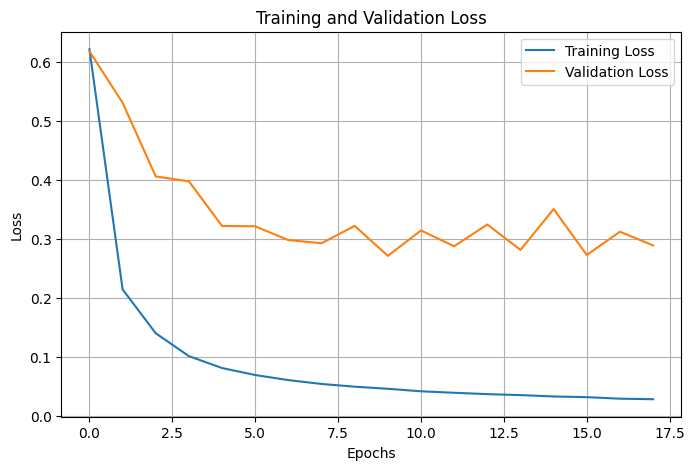

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(best_history["train_loss"], label="Training Loss")
plt.plot(best_history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

Tracer la courbe Accuracy / Epochs

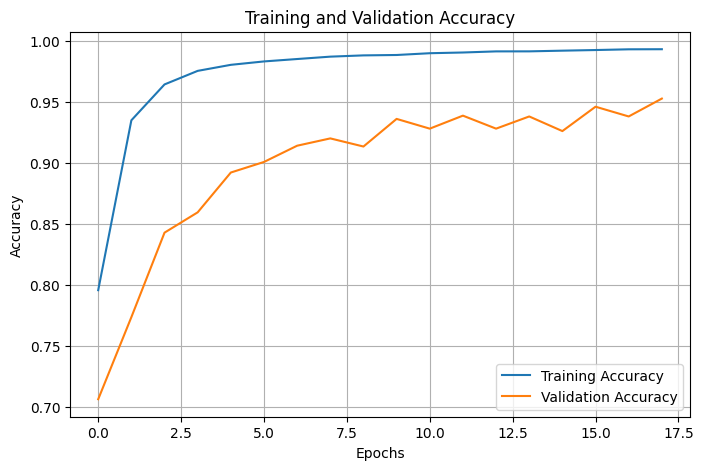

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(best_history["train_acc"], label="Training Accuracy")
plt.plot(best_history["val_acc"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

**Évaluer le modèle sur les données de test**

Préparer une fonction de prédiction

In [53]:
def predict_model(model, X, batch_size=256):
    model.eval()
    predictions = []

    X_tensor = torch.tensor(
        np.asarray(X, dtype=np.float32),
        dtype=torch.float32
    )

    with torch.no_grad():
        for start in range(0, len(X_tensor), batch_size):
            batch = X_tensor[start:start + batch_size].to(device)
            outputs = model(batch)
            preds = torch.argmax(outputs, dim=1)
            predictions.extend(preds.cpu().numpy())

    return np.array(predictions)

Calculer les prédictions

In [54]:
y_train_pred = predict_model(best_model, X_train_balanced)
y_test_pred = predict_model(best_model, X_test_scaled)

Afficher les métriques principales

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=== TRAINING SET (balanced) ===")
print("Accuracy :", accuracy_score(y_train_balanced, y_train_pred))
print("Precision macro :", precision_score(
    y_train_balanced, y_train_pred, average="macro", zero_division=0
))
print("Sensitivity / Recall macro :", recall_score(
    y_train_balanced, y_train_pred, average="macro", zero_division=0
))
print("F1 macro :", f1_score(
    y_train_balanced, y_train_pred, average="macro", zero_division=0
))

print("\n=== TEST SET (original distribution) ===")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("Precision macro :", precision_score(
    y_test, y_test_pred, average="macro", zero_division=0
))
print("Sensitivity / Recall macro :", recall_score(
    y_test, y_test_pred, average="macro", zero_division=0
))
print("F1 macro :", f1_score(
    y_test, y_test_pred, average="macro", zero_division=0
))

=== TRAINING SET (balanced) ===
Accuracy : 0.9912916913360963
Precision macro : 0.9914205727999791
Sensitivity / Recall macro : 0.9912916913360963
F1 macro : 0.991207402552413

=== TEST SET (original distribution) ===
Accuracy : 0.9366666666666666
Precision macro : 0.49672610453666244
Sensitivity / Recall macro : 0.6589838974263739
F1 macro : 0.5519038827244446


Rapport détaillé par classe

In [56]:
print(classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(output_dim),
    target_names=label_encoder.classes_,
    zero_division=0
))

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.44      0.94      0.60        17
              No Failure       0.99      0.94      0.97      1448
      Overstrain Failure       0.75      1.00      0.86        12
           Power Failure       0.76      0.93      0.84        14
         Random Failures       0.00      0.00      0.00         2
       Tool Wear Failure       0.03      0.14      0.04         7

                accuracy                           0.94      1500
               macro avg       0.50      0.66      0.55      1500
            weighted avg       0.98      0.94      0.96      1500



Afficher la matrice de confusion

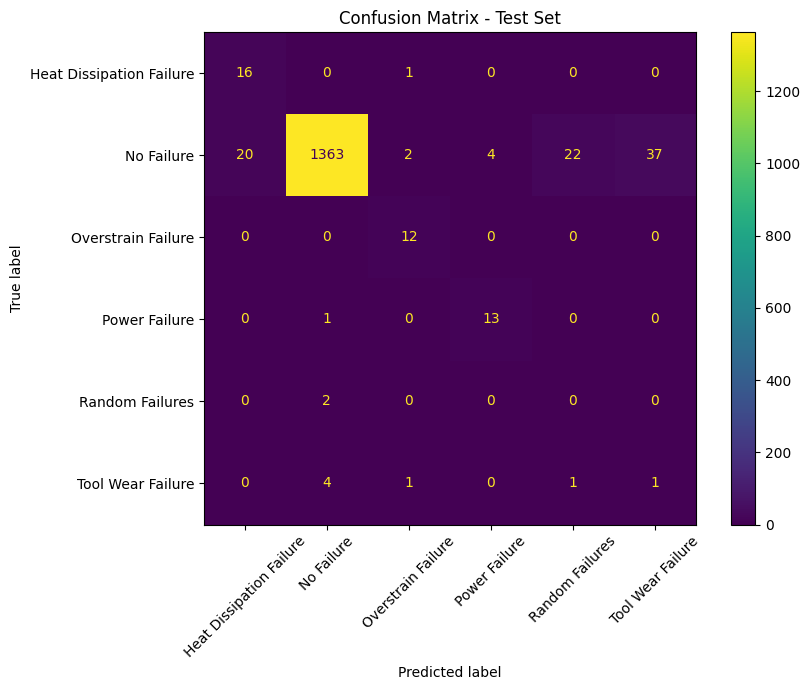

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=np.arange(output_dim)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()

**Tester plusieurs techniques de régularisation**

Vérifier que train_model accepte le dropout et le weight decay

In [59]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0
)

Entraîner et comparer les quatre modèles

In [60]:
configs = {
    "Base": {"dropout": 0.0, "weight_decay": 0.0},
    "Dropout": {"dropout": 0.3, "weight_decay": 0.0},
    "Weight Decay": {"dropout": 0.0, "weight_decay": 0.0001},
    "Dropout + Weight Decay": {
        "dropout": 0.3,
        "weight_decay": 0.0001
    }
}

results = []

for name, config in configs.items():
    print(f"\nEntraînement : {name}")

    model_reg = MLPClassifierTorch(
        input_dim=input_dim,
        output_dim=output_dim,
        hidden1=best_hidden1,
        hidden2=32,
        dropout=config["dropout"]
    ).to(device)

    model_reg, history_reg = train_model(
        model_reg,
        X_train_balanced,
        y_train_balanced,
        X_val_scaled,
        y_val,
        epochs=best_epochs,
        batch_size=best_batch_size,
        lr=best_lr,
        weight_decay=config["weight_decay"],
        patience=8
    )

    y_pred = predict_model(model_reg, X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall Macro": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))


Entraînement : Base
Early stopping à l'époque 15

Entraînement : Dropout

Entraînement : Weight Decay

Entraînement : Dropout + Weight Decay
                    Model  Accuracy  Recall Macro  F1 Macro
0                    Base    0.9293        0.7051    0.5007
1                 Dropout    0.8713        0.7069    0.4292
2            Weight Decay    0.9400        0.6596    0.5329
3  Dropout + Weight Decay    0.8787        0.6608    0.4543


Visualiser la comparaison

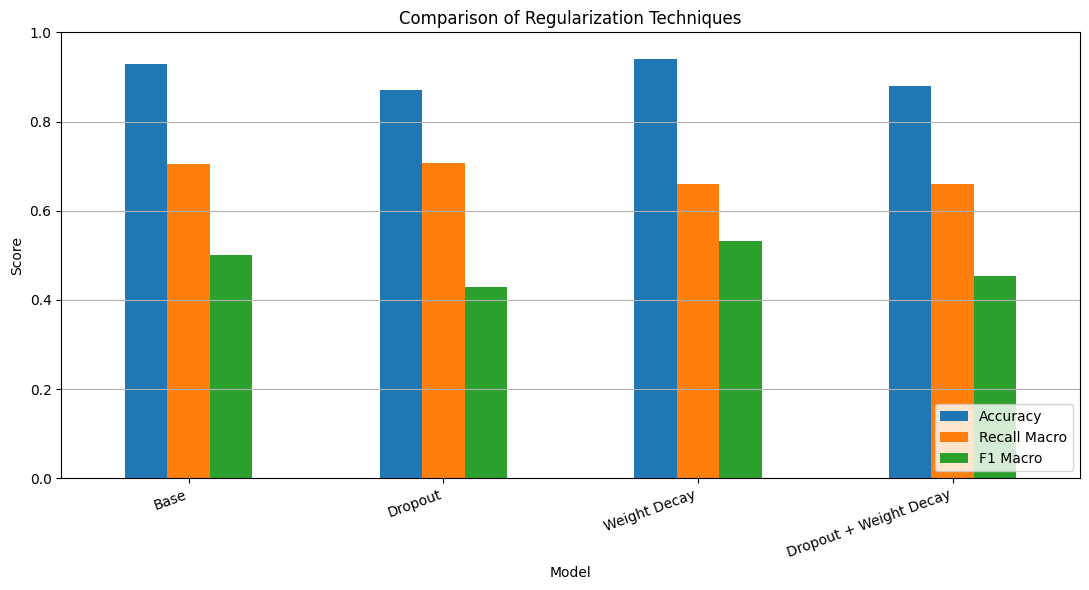

In [61]:
results_plot = results_df.set_index("Model")

results_plot[["Accuracy", "Recall Macro", "F1 Macro"]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Regularization Techniques")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()